# 58 · PPO: old policy를 고정하고 같은 배치를 다시 쓰기

📎 **이번 질문** · 정책을 이미 한 번 바꿨는데 같은 rollout을 다시 학습해도 될까요? 확률비의 clip은 무엇을 제한할까요?

수집 당시의 행동 확률·가치·GAE 타깃을 복사해 고정합니다. 현재 정책과 old policy의 확률비로 surrogate를 만들고, advantage 부호에 따라 다른 clip 가지를 미분합니다. value·entropy까지 포함한 작은 실제 PPO를 학습해 KL과 return을 함께 읽습니다.

- 준비물: [15 실험 검산](../02_연결/15_experiments_evaluation.ipynb), [56 REINFORCE](56_reinforce.ipynb), [57 Actor–Critic·GAE](57_actor_critic_gae.ipynb).
- 도착점: old log확률·확률비, 두 부호의 clip, 고정 rollout 타깃, 전체 목적·미분, 여러 epoch 재사용과 평가.
- 54·57과 같은 시작보상0의4상태 환경입니다. 56의 시작 보상 변경은 여기서 사용하지 않습니다. 확률정책의 정확 J와 최적1.8을 구분합니다.
- actor는3→2 선형 softmax(6개), critic은3→1 선형값(3개)입니다. 큰 PPO benchmark 재현이 아니라 정확히 읽고 검산할 작은 구현입니다.

### 읽는 법

| 표시 | 뜻 | 읽는 방법 |
|---|---|---|
| 🔑 핵심 | 수식·구현 | old 배열과 현재 모델을 나눕니다 |
| 🔍 확인 | 그림·검산 | clip과 실제 정책 변화를 비교합니다 |
| 📎 참고 | 용어·코드 | 평균 분모와 경계를 확인합니다 |
| ✏️ 연습 | 한두 줄 구현 | 작은 독립 답과 대조합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. old logπ·old V·advantage·return은 한 rollout을 재사용하는 모든 epoch에서 고정합니다.
2. clip은 좋은 방향의 surrogate 증가를 평평하게 만듭니다. 모든 확률비나 KL을 강제로 일정 범위에 가두는 연산이 아닙니다.
3. 같은 상호작용 예산이라도 epoch 수가 다르면 optimizer 예산이 다릅니다. 정확 J·KL·실제 수집 return을 구분합니다.

| 기호 | shape | 뜻 |
|---|---|---|
| states,actions,rewards | `(B,T)` | B개의 두 전이 경로(T=2) |
| X,θ,w | `(N,3),(3,2),(3,)` | N=2B개 one-hot 입력·actor·critic |
| old_logp,r,A,Rλ | `(N,)` | 선택 행동의 old log확률·비율·고정 타깃 |
| old_probs,old_log_probs | `(N,2)` | 관측 상태에서 old 전체 행동분포·로그 |

[전체 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/ppo_plots.py)

In [1]:
# 준비 셀: 수치계산·그림·연습 검사 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots, run_check
from src.utils.ppo_plots import (
    plot_policy_ratios, plot_signed_clip, plot_ppo_rollout, plot_ppo_objective,
    plot_ppo_protocol, plot_ppo_learning, plot_ppo_epochs, plot_ppo_final,
)
setup_plots()
print('고정 old rollout · clipped surrogate + value − entropy · NumPy 전체미분')

고정 old rollout · clipped surrogate + value − entropy · NumPy 전체미분


## 🔑 1. old policy가 선택한 행동의 확률을 저장합니다

**이 절에서 가져갈 것:** 확률비의 분모는 데이터 수집 당시 정책이고, epoch마다 다시 계산해 바꾸면 안 됩니다.

배달 시작0에서 행동0은 안전2, 행동1은 위험1입니다. 시작 보상은0이고, 안전의 두 행동은 모두 .7, 위험의 행동0은2·행동1은−14를 받은 뒤 종료3으로 갑니다. γ=.9이며 항상 두 전이입니다.

> **용어**
>
> - **old policy πold**는 이번 rollout을 실제로 수집한 정책의 복사본입니다. 선택한 행동의 log확률을 저장합니다.
> - **확률비 r**는 현재 정책이 그 행동을 고를 확률을 old 확률로 나눈 수입니다. 여기의 r는 즉시 보상과 다른 기호이며 코드에서 보상은 `rewards`, 비율은 `ratio`입니다.
> - **surrogate**는 old 상태·행동 표본과 고정 advantage로 만드는 정책 갱신 목적입니다. 여러 epoch 뒤의 실제 J와 같은 함수는 아닙니다.

$$r_j(\theta)=\frac{\pi_\theta(a_j|s_j)}{\pi_{old}(a_j|s_j)}
=\exp(\log\pi_\theta(a_j|s_j)-old\_logp_j).$$

θ=θold이면 모든 비율은1입니다. 현재 분자를 분모에도 다시 넣으면 이후에도 항상1이 되어 정책이 얼마나 변했는지 잃습니다. softmax로 모든 행동에 양의 확률을 주고, log확률은 안정적인 log-sum-exp 형태로 계산합니다.

> **코드** · `X=np.eye(3)[states]`는 상태 번호를 one-hot으로 바꿉니다. `Q[np.arange(N),actions]` 형태는 각 행의 선택 행동을 고릅니다. `np.exp(log_new-log_old)`는 먼저 확률을 나누는 대신 로그 차이로 비율을 계산합니다.

> **용어** · **epoch**는 이번에 모은 배치를 한 번 전체 사용한 학습 반복입니다. 여기서는 mini-batch로 나누지 않아 한 epoch마다 full-batch optimizer 갱신 한 번을 합니다.

In [2]:
example_old = np.array([.5,.8,.2])
example_current = np.array([.8,.6,.4])
example_old_log = np.log(example_old)
example_ratio = np.exp(np.log(example_current)-example_old_log)
ratio_loop = np.zeros(3)
for index in range(3):
    ratio_loop[index] = example_current[index]/example_old[index]

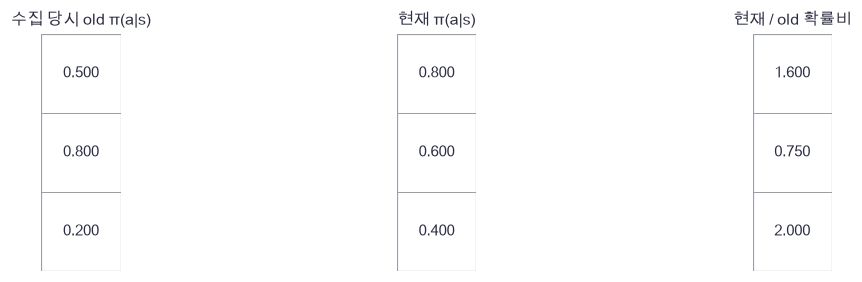

In [3]:
plot_policy_ratios(example_old, example_current, example_ratio)

🔍 **확인** · 현재 확률이 커져도 old 분모는 그대로입니다. 여기의 비율은 한 행동의 국소 보정이며, 달라진 현재 정책의 전체 상태 방문분포까지 정확히 교정하는 경로 importance sampling은 아닙니다. PPO는 이 old 분포의 surrogate를 잠깐 최적화한 뒤 새 경로를 수집합니다.

In [4]:
def ppo_policy(theta,x):
    """X:(N,3), theta:(3,2)의 안정적인 categorical 확률·log확률:(N,2)."""
    logits = x@theta
    shifted = logits-logits.max(axis=1,keepdims=True)
    log_probabilities = shifted-np.log(np.exp(shifted).sum(axis=1,keepdims=True))
    return np.exp(log_probabilities),log_probabilities

In [5]:
def ppo_exact(theta,gamma=0.9):
    """시작보상0의4상태환경에서 현재 확률정책의 정확 J와 비종료 V:(3,)를 계산합니다."""
    policy,log_probabilities = ppo_policy(theta,np.eye(3))
    risky = policy[1]@np.array([2.,-14.])
    value = gamma*(policy[0,0]*.7+policy[0,1]*risky)
    return float(value),np.array([value,risky,.7])

In [6]:
# 쓰는 것: example_old_log, example_ratio, ratio_loop (위 절의 정의·실행 셀)
np.testing.assert_allclose(example_ratio,[1.6,.75,2.])  # 검산:현재/수집당시확률
np.testing.assert_allclose(example_ratio,ratio_loop)  # 검산:로그차벡터화=직접나눗셈반복문
np.testing.assert_allclose(np.exp(example_old_log-example_old_log),1.)  # 검산:old정책자신의비율은1
uniform_theta = np.zeros((3,2))
uniform_policy,uniform_log = ppo_policy(uniform_theta,np.eye(3))
np.testing.assert_allclose(uniform_policy,.5)  # 검산:동일logits는균등정책
np.testing.assert_allclose(ppo_exact(uniform_theta)[0],-2.385)  # 검산:.9×(.5×.7+.5×(1−7))
print('old 비율·균등 정책·정확 시작 J 통과')

old 비율·균등 정책·정확 시작 J 통과


### ✏️ 연습 1 · old log확률에서 비율

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

old_logp를 상수로 두고 현재와의 차이를 지수화하세요.

In [7]:
def exercise_ratio(current_logp, old_logp):
    """old log확률에서 비율의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return ratio

In [8]:
def check_ratio(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.log(np.array([.8,.2])),np.log(np.array([.5,.5]))),[1.6,.4])  # 검산:확률나눗셈
    print('old 확률비 통과')

run_check(check_ratio,exercise_ratio,hint='분모를 현재 정책으로 덮어쓰지 않습니다.')

☐ exercise_ratio: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 분모를 현재 정책으로 덮어쓰지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
ratio = np.exp(current_logp - old_logp)
```

</details>

## 🔑 2. advantage 부호에 따라 clip의 평평한 쪽이 바뀝니다

**이 절에서 가져갈 것:** ratio가 범위를 벗어났다는 사실과 surrogate 미분이0이 된다는 사실은 다릅니다.

좋은 행동의 확률은 높이고 나쁜 행동의 확률은 낮추고 싶습니다. 너무 많이 좋아진 것처럼 계산되는 방향의 이득을 잘라 냅니다. εclip=.2일 때

$$f(r,A)=\min\{rA,\operatorname{clip}(r,.8,1.2)A\}.$$

> **용어**
>
> - **PPO-Clip**은 확률비와 advantage의 곱을 위 min 식으로 제한하는 정책 최적화 방식입니다.
> - **미분 포화**는 해당 표본의 surrogate가 ratio 변화에 평평해져 그 항의 미분이0인 경우입니다. A>0·r>1.2 또는 A<0·r<.8에서 일어납니다.
> - **범위 초과율**은 `abs(ratio−1)>.2`인 표본 비율입니다. 나쁜 방향으로 많이 움직인 표본의 미분은 여전히 살아 있을 수 있습니다.

A>0에서는 r가1.2보다 커질 때 추가 이득을 막습니다. A<0에서는 r가.8보다 작아질 때 추가 이득을 막습니다. 나쁜 행동의 확률이 오히려 커진 r>1.2·A<0 사례는 벌점을 계속 받습니다.

> **코드** · `np.clip(x,lower,upper)`는 값을 범위 안으로 자르고, `np.minimum(a,b)`는 두 배열의 같은 위치 중 작은 값을 고릅니다. `&`와 `|`는 괄호로 감싼 원소별 조건을 결합합니다.

> **코드** · `np.linspace(a,b,N)`은 두 끝점을 포함한 N개 간격 점을 만듭니다. `np.stack([a,b])`는 두 배열을 새 행 축으로 쌓습니다. boolean 배열 앞에 물결표 연산자를 붙이면 참·거짓을 뒤집습니다.

In [9]:
ratio_axis = np.linspace(.4,1.6,121)
raw_curves = np.stack([ratio_axis,-ratio_axis])
clipped_curves = np.stack([np.minimum(ratio_axis,np.clip(ratio_axis,.8,1.2)),
                           np.minimum(-ratio_axis,-np.clip(ratio_axis,.8,1.2))])
branch_ratios = np.array([.7,1.3,.7,1.3])
branch_advantages = np.array([1.,1.,-1.,-1.])
branch_active = np.array([True,False,False,True])
branch_table = np.column_stack([branch_ratios,branch_advantages,branch_active])

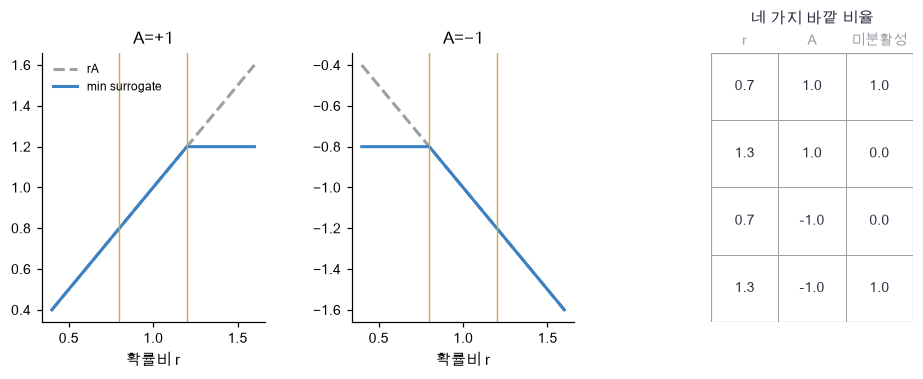

In [10]:
plot_signed_clip(ratio_axis, raw_curves, clipped_curves, branch_table)

🔍 **확인** · 표의 네 비율은 모두 범위 밖이지만 두 경우만 평평합니다. 따라서 범위 초과율1과 미분 포화율.5를 구분해야 합니다. clip 경계에서는 미분이 유일하지 않으므로 수치 미분 검산은 경계에서 떨어진 점을 사용합니다. 구현은 정확히 경계인 점에서 살아 있는 가지의 미분을 택합니다.

In [11]:
def clipped_surrogate(ratio,advantages,clip=0.2):
    """원소별 min(rA,clip(r)A)와 미분이 살아있는 마스크를 반환합니다. clip=None은 대조실험."""
    if clip is None:
        return ratio*advantages,np.ones_like(ratio,dtype=bool)
    clipped = np.clip(ratio,1-clip,1+clip)
    terms = np.minimum(ratio*advantages,clipped*advantages)
    saturated = ((advantages>0)&(ratio>1+clip))|((advantages<0)&(ratio<1-clip))
    return terms,~saturated

In [12]:
branch_terms,computed_active = clipped_surrogate(branch_ratios,branch_advantages,.2)
np.testing.assert_allclose(branch_terms,[.7,1.2,-.8,-1.3])  # 검산:advantage양·음의4경우손계산
np.testing.assert_array_equal(computed_active,branch_active)  # 검산:좋은방향의이득만포화
np.testing.assert_allclose(np.mean(np.abs(branch_ratios-1)>.2),1.)  # 검산:모든비율이범위밖
np.testing.assert_allclose(np.mean(~computed_active),.5)  # 검산:하지만미분포화는절반
np.testing.assert_allclose(clipped_surrogate(branch_ratios,branch_advantages,None)[0],branch_ratios*branch_advantages)  # 검산:clip없는대조는rA
print('clip 네 가지·범위 초과/미분 포화 분리 통과')

clip 네 가지·범위 초과/미분 포화 분리 통과


### ✏️ 연습 2 · 부호를 포함한 surrogate

rA와 clipped(r)A 중 작은 쪽을 구하세요.

In [13]:
def exercise_surrogate(ratio, advantage, clip):
    """부호를 포함한 surrogate의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return value

In [14]:
def check_surrogate(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.7,1.3]),np.array([-1.,-1.]),.2),[-.8,-1.3])  # 검산:음수A의양쪽경우
    print('signed clip 통과')

run_check(check_surrogate,exercise_surrogate,hint='ratio만 자르고 끝내면 min 가지를 빠뜨립니다.')

☐ exercise_surrogate: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: ratio만 자르고 끝내면 min 가지를 빠뜨립니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.minimum(ratio * advantage, np.clip(ratio, 1-clip, 1+clip) * advantage)
```

</details>

## 🔑 3. rollout의 old 가치와 GAE 타깃을 먼저 고정합니다

**이 절에서 가져갈 것:** 한 배치의 여러 epoch 동안 old logπ·old V·advantage·critic return을 바꾸지 않습니다.

완료한 안전 경로와 위험 실수 경로를 하나씩 모았습니다. epoch마다 critic이 좋아지더라도 같은 데이터의 A를 새 critic으로 다시 만들지 않습니다. 이번 rollout을 만들 당시의 값으로 모두 계산해 둡니다.

$$\delta_t=r_t+\gamma(1-d_t)V_{old}(s_{t+1})-V_{old}(s_t),$$
$$\widehat A_t=\delta_t+\gamma\lambda(1-b_t)\widehat A_{t+1},\qquad
\widehat R_t=V_{old}(s_t)+\widehat A_t.$$

d는 진짜 종료, b는 수집 경계입니다. 외부 수집 제한은 d=0·b=1이므로 마지막 실제 도착 상태의 V를 붙이되 다른 경로 잔차를 잇지 않습니다. 실제 학습은 완료한 T=2 경로만 모으며 λ=.95를 고정합니다.

> **용어** · **고정 rollout 배치**는 상태·행동·old 확률·old 가치·타깃을 복사해 한 묶음으로 보관한 데이터입니다. 다음 rollout을 새 정책으로 모을 때 새 old 배치를 만듭니다.

> **코드** · `.copy()`는 현재 모델과 저장 데이터를 분리합니다. `states.ravel()`은 `(B,2)`를 행 순서대로 펼칩니다. `np.tile([False,True],(B,1))`는 완료한 각 경로의 마지막 전이만 종료로 표시합니다.

In [15]:
rollout_states = np.array([[0,2],[0,1]])
rollout_actions = np.array([[0,0],[1,1]])
rollout_rewards = np.array([[0.,.7],[0.,-14.]])
old_theta = np.zeros((3,2))
old_critic = np.array([.5,.4,.7])
rollout_values = old_critic[rollout_states]
rollout_next = np.column_stack([old_critic[rollout_states[:,1]],np.zeros(2)])
rollout_terminal = np.array([[False,True],[False,True]])
rollout_delta = rollout_rewards+.9*(1-rollout_terminal)*rollout_next-rollout_values
rollout_advantage = rollout_delta.copy()
rollout_advantage[:,0] += .9*.95*rollout_delta[:,1]
rollout_returns = rollout_values+rollout_advantage

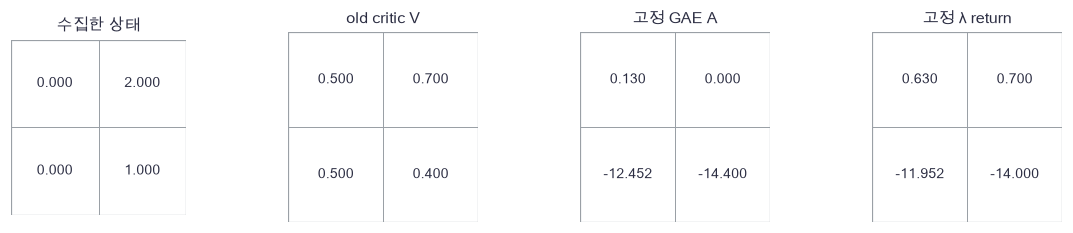

In [16]:
plot_ppo_rollout(rollout_states, rollout_values, rollout_advantage, rollout_returns)

🔍 **확인** · 두 경로 모두 마지막에는 실제 보상을 타깃으로 씁니다. 시작의 λ 타깃에는 이전 critic의 영향이 남습니다. 값이 크거나 음수라고 임의로 자르지 않고, 이 고정 숫자를 다음 절의 actor·critic 목적에 넣습니다.

In [17]:
def ppo_gae(rewards,values,next_values,terminated,boundary,gamma=0.9,lam=0.95):
    """(B,T)의 GAE: 진짜종료는bootstrap차단, 수집경계는다음잔차연결차단."""
    delta = rewards+gamma*(1-terminated.astype(float))*next_values-values
    advantage = np.zeros_like(delta)
    running = np.zeros(len(delta))
    for time in reversed(range(delta.shape[1])):
        running = delta[:,time]+gamma*lam*(1-boundary[:,time].astype(float))*running
        advantage[:,time] = running
    return advantage

In [18]:
def frozen_ppo_batch(theta,critic,states,actions,rewards,lam=0.95):
    """완료2전이경로에서old확률·oldV·GAE·return을복사고정합니다. 이후epoch에서재계산하지않습니다."""
    # 쓰는 것: ppo_policy (위 절의 정의·실행 셀)
    x = np.eye(3)[states.ravel()]
    probabilities,log_probabilities = ppo_policy(theta,x)
    old_values = (x@critic).reshape(states.shape).copy()
    next_values = np.column_stack([critic[states[:,1]],np.zeros(len(states))])
    terminal = np.tile(np.array([False,True]),(len(states),1))
    advantages = ppo_gae(rewards,old_values,next_values,terminal,terminal,lam=lam)
    returns = old_values+advantages
    flat_actions = actions.ravel().copy()
    return {'x':x,'actions':flat_actions,'discounts':np.tile([1.,.9],len(states)),
            'advantages':advantages.ravel().copy(),'returns':returns.ravel().copy(),
            'old_logp':log_probabilities[np.arange(len(x)),flat_actions].copy(),
            'old_probs':probabilities.copy(),'old_log_probs':log_probabilities.copy(),
            'old_values':old_values.ravel().copy(),'episodes':len(states)}

In [19]:
# 쓰는 것: old_critic, old_theta, rollout_actions, rollout_advantage, rollout_returns, rollout_rewards, rollout_states (위 절의 정의·실행 셀)
frozen_batch = frozen_ppo_batch(old_theta,old_critic,rollout_states,rollout_actions,rollout_rewards)
np.testing.assert_allclose(frozen_batch['advantages'].reshape(2,2),rollout_advantage)  # 검산:고정배치GAE=직접두전이계산
np.testing.assert_allclose(frozen_batch['returns'].reshape(2,2),rollout_returns)  # 검산:oldV+GAE
frozen_values = frozen_batch['old_values'].copy()
old_critic[0] += 10.
np.testing.assert_array_equal(frozen_batch['old_values'],frozen_values)  # 검산:모델배열변경은저장oldV를바꾸지않음
old_critic[0] -= 10.
cutoff_advantage = ppo_gae(np.array([[0.,100.]]),np.array([[.5,20.]]),np.array([[.4,99.]]),np.array([[False,True]]),np.array([[True,True]]),lam=1.)
np.testing.assert_allclose(cutoff_advantage[0,0],-.14)  # 검산:외부수집끝bootstrap유지·다음경로잔차차단
print('old배치 복사·고정 타깃·종료/수집 경계 통과')

old배치 복사·고정 타깃·종료/수집 경계 통과


### ✏️ 연습 3 · λ return을 고정합니다

old value에 GAE를 더해 새 배열로 저장하세요.

In [20]:
def exercise_return_target(old_values, advantages):
    """λ return을 고정합니다의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return targets

In [21]:
def check_return_target(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.5,.4]),np.array([1.3,1.6])),[1.8,2.])  # 검산:oldV+완료λ1advantage
    print('고정 value 타깃 통과')

run_check(check_return_target,exercise_return_target,hint='새 critic 값으로 다시 계산하지 않습니다.')

☐ exercise_return_target: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 새 critic 값으로 다시 계산하지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
targets = (old_values + advantages).copy()
```

</details>

## 🔑 4. policy·value·entropy 목적을 각각 미분합니다

**이 절에서 가져갈 것:** actor와 entropy는 할인된 episode 평균, value는 transition 평균이며 clip의 미분 가지를 고정 타깃에서 검산합니다.

같은 배치를 재사용할 때 actor의 확률과 critic의 현재 예측만 바뀝니다. 이 단원의 전체 최소화 목적은
$$L=L_\pi+c_VL_V-\beta H,\quad
L_\pi=-\frac1B\sum_j\gamma^{t_j}f(r_j,\widehat A_j),$$
$$L_V=\frac1{2N}\sum_j(V_w(s_j)-\widehat R_j)^2,\quad
H=\frac1B\sum_j\gamma^{t_j}\left[-\sum_a\pi_\theta(a|s_j)\log\pi_\theta(a|s_j)\right].$$

B는 episode 수, N=2B는 유효 전이 수입니다. cV=.5·β=.01입니다. entropy도 actor와 같은 **γ^t 가중·episode 분모**이고, value는 할인 없이 **transition 분모**입니다. 다른 구현의 평균 규약과 수치를 그대로 비교하지 않습니다.

> **용어**
>
> - **entropy**는 행동 확률이 얼마나 퍼져 있는지의 값입니다. 전체 행동을 합하며, 손실에서 빼므로 확률이 너무 빨리 한 행동에 몰리는 것을 완화할 수 있습니다.
> - **categorical KL(old || current)**는 한 상태의 두 전체 행동분포 차이입니다. 여기서는 관측된 N개 상태에서 정확한 행동 합을 구한 뒤 평균합니다. 전체 환경의 상태분포에 대한 정확 기대 KL은 아닙니다.

cj=γ^tj/B, pj=πθ(·|sj), ej=선택 행동 one-hot, hj=−Σpjlogpj라 쓰면
$$d\ell_j=c_jr_j\widehat A_j\mathbf1[\mathrm{active}](p_j-e_j)
+\beta c_jp_j\odot(\log p_j+h_j),$$
$$d\theta=X^Td\ell,\quad dw=\frac{c_V}{N}X^T(V-\widehat R),\quad
dX=d\ell\theta^T+\frac{c_V}{N}(V-\widehat R)w^T.$$

clip 범위 밖에서도 entropy 항이나 다른 표본이 같은 정책 파라미터를 움직일 수 있습니다. 따라서 surrogate clipping은 확률비의 강제 제약이나 단조 성능 향상 보장이 아닙니다. 이번에는 value clipping·advantage 정규화·KL 조기 중단을 추가하지 않고, 무엇이 변하는지 기록합니다.

> **코드** · `np.ndindex(array.shape)`는 전체 원소를 하나씩 미분 검산합니다. `gradients['theta']`와 `gradients['critic']`는 서로 다른 모델의 기울기입니다. `clip=None`인 대조는 surrogate를 자르지 않지만 범위 초과 진단은 같은 .2 기준으로 기록합니다.

In [22]:
# 쓰는 것: branch_terms (위 절의 정의·실행 셀)
objective_discounts = np.array([1.,.9,1.,.9])
objective_policy = np.array([[.8,.2],[.3,.7],[.6,.4],[.9,.1]])
objective_actor = -np.sum(objective_discounts*branch_terms)/2
objective_value = .5*np.mean((np.array([.5,.4,.3,.7])-np.array([1.,.2,-.1,.5]))**2)
objective_entropy = np.sum(objective_discounts*(-np.sum(objective_policy*np.log(objective_policy),axis=1)))/2
objective_components = np.array([objective_actor,objective_value,objective_entropy])
objective_coefficients = np.array([1.,.5,-.01])
objective_contributions = objective_components*objective_coefficients
print('각항 기여와 총손실:',objective_contributions,objective_contributions.sum())

각항 기여와 총손실: [ 0.095       0.030625   -0.01007883] 0.11554616680775434


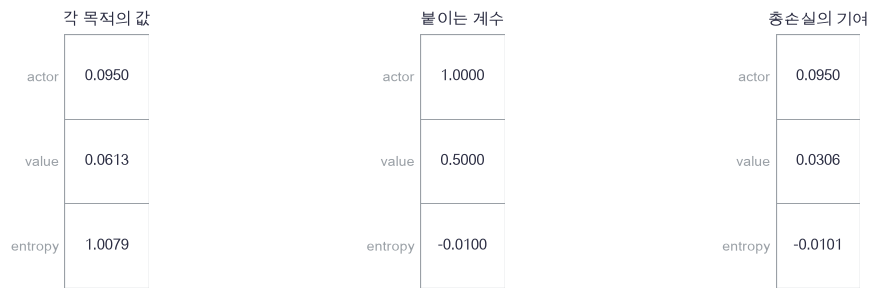

In [23]:
plot_ppo_objective(objective_components, objective_coefficients, objective_contributions)

🔍 **확인** · entropy의 계수는 음수이고, value 계수.5는 이미 value loss 안의1/2와 별개입니다. 미분 검산에서는 old 확률·advantage·return을 그대로 둡니다. 매 perturbation마다 GAE나 old logπ를 다시 계산하면 다른 함수를 검사하게 됩니다.

In [24]:
def ppo_loss(theta,critic,data,clip=0.2,entropy_coefficient=0.01,value_coefficient=0.5):
    """고정old데이터의PPO surrogate+value−entropy와 actor·critic·X 전체미분·진단을반환합니다."""
    # 쓰는 것: clipped_surrogate, ppo_policy (위 절의 정의·실행 셀)
    # 1. 분모 oldlogp와advantage는고정하고현재정책의분자만변경합니다.
    x,actions = data['x'],data['actions']
    probabilities,log_probabilities = ppo_policy(theta,x)
    ratio = np.exp(log_probabilities[np.arange(len(x)),actions]-data['old_logp'])
    terms,active = clipped_surrogate(ratio,data['advantages'],clip)
    weights = data['discounts']/data['episodes']
    actor_loss = -np.sum(weights*terms)
    entropy_rows = -np.sum(probabilities*log_probabilities,axis=1)
    entropy = np.sum(weights*entropy_rows)
    residual = x@critic-data['returns']
    value_loss = 0.5*np.mean(residual**2)
    # 2. clip된가지와old가지에는미분을흘리지않고entropy는전체행동분포로미분합니다.
    coefficients = weights*data['advantages']*ratio*active
    d_logits = coefficients[:,None]*(probabilities-np.eye(2)[actions])
    d_logits += entropy_coefficient*weights[:,None]*probabilities*(log_probabilities+entropy_rows[:,None])
    d_values = value_coefficient*residual/len(x)
    gradients = {'theta':x.T@d_logits,'critic':x.T@d_values,
                 'X':d_logits@theta.T+d_values[:,None]*critic[None,:]}
    # 3. KL은관측상태의전체categorical분포에서정확계산합니다. 범위초과율과기울기포화를구분합니다.
    threshold = 0.2 if clip is None else clip
    kl = np.mean(np.sum(data['old_probs']*(data['old_log_probs']-log_probabilities),axis=1))
    metrics = {'actor':actor_loss,'value':value_loss,'entropy':entropy,'kl':kl,
               'outside':np.mean(np.abs(ratio-1)>threshold),'saturated':np.mean(~active),
               'ratio_min':ratio.min(),'ratio_max':ratio.max()}
    total = actor_loss+value_coefficient*value_loss-entropy_coefficient*entropy
    return float(total),gradients,metrics

In [25]:
def check_ppo_gradient(theta,critic,data,clip=.2,step=1e-5):
    """clip경계에서떨어진고정배치의actor·critic·입력전체중심차분을검사합니다."""
    analytic = ppo_loss(theta,critic,data,clip)[1]
    errors = {}
    for name,array in [('theta',theta),('critic',critic),('X',data['x'])]:
        numeric = np.zeros_like(array)
        for index in np.ndindex(array.shape):
            original = array[index]
            array[index] = original+step
            plus = ppo_loss(theta,critic,data,clip)[0]
            array[index] = original-step
            minus = ppo_loss(theta,critic,data,clip)[0]
            array[index] = original
            numeric[index] = (plus-minus)/(2*step)
        errors[name] = np.max(np.abs(numeric-analytic[name]))
    return errors

In [26]:
# 쓰는 것: frozen_ppo_batch (위 절의 정의·실행 셀)
gradient_old = np.array([[.5,-.5],[.1,-.1],[-.2,.2]])
gradient_theta = np.array([[1.2,-1.2],[.05,-.05],[-.7,.7]])
gradient_critic = np.array([.3,-.2,.1])
gradient_states = np.array([[0,2],[0,1],[0,1]])
gradient_actions = np.array([[0,0],[1,0],[1,1]])
gradient_rewards = np.array([[0.,.7],[0.,2.],[0.,-14.]])
gradient_data = frozen_ppo_batch(gradient_old,gradient_critic,gradient_states,gradient_actions,gradient_rewards)
gradient_data['advantages'] = np.array([1.,-.3,-1.,.5,-1.,-.6])  # 수치검산용두부호상수; 실제학습은GAE값을그대로사용
gradient_errors = check_ppo_gradient(gradient_theta,gradient_critic,gradient_data)
assert max(gradient_errors.values())<1e-7, 'clip경계밖의actor6개·critic3개·입력전체미분이맞아야합니다'
loss,gradients,metrics = ppo_loss(gradient_theta,gradient_critic,gradient_data)
print('전체 목적 중심차분:',gradient_errors,'· KL:',metrics['kl'])
assert metrics['kl']>=-1e-12, '전체categorical KL은수치오차범위에서음수가아닙니다'

전체 목적 중심차분:

 {'theta': np.float64(1.8812951196878203e-11), 'critic': np.float64(1.351184719666776e-10), 'X': np.float64(1.4874607101589277e-10)} · KL: 0.09357904031894333


In [27]:
# 쓰는 것: ppo_policy (위 절의 정의·실행 셀)
old_log_before = gradient_data['old_logp'].copy()
old_values_before = gradient_data['old_values'].copy()
advantages_before = gradient_data['advantages'].copy()
returns_before = gradient_data['returns'].copy()
updated_theta = gradient_theta-.05*gradients['theta']
updated_critic = gradient_critic-.4*gradients['critic']
after_metrics = ppo_loss(updated_theta,updated_critic,gradient_data)[2]
np.testing.assert_array_equal(gradient_data['old_logp'],old_log_before)  # 검산:epoch갱신뒤old확률고정
np.testing.assert_array_equal(gradient_data['old_values'],old_values_before)  # 검산:critic갱신뒤oldV고정
np.testing.assert_array_equal(gradient_data['advantages'],advantages_before)  # 검산:A고정
np.testing.assert_array_equal(gradient_data['returns'],returns_before)  # 검산:criticreturn고정
old_point = ppo_loss(gradient_old,gradient_critic,gradient_data,entropy_coefficient=0.,value_coefficient=0.)
probabilities,log_probabilities = ppo_policy(gradient_old,gradient_data['x'])
vanilla_coefficients = gradient_data['discounts']*gradient_data['advantages']/gradient_data['episodes']
vanilla_gradient = gradient_data['x'].T@(vanilla_coefficients[:,None]*(probabilities-np.eye(2)[gradient_data['actions']]))
np.testing.assert_allclose(old_point[1]['theta'],vanilla_gradient)  # 검산:ratio1에서고정배치policygradient와동일
np.testing.assert_allclose(old_point[1]['critic'],0.)  # 검산:value계수0이면critic미분0
print('old 배열 네 가지 불변·ratio1 미분·value계수0 통과')

old 배열 네 가지 불변·ratio1 미분·value계수0 통과


### ✏️ 연습 4 · value 목적의 계수와 분모

이미 계산한 residual=V−return에 cV와 전이 수를 반영하세요.

In [28]:
def exercise_value_gradient(x, residual, value_coefficient):
    """value 목적의 계수와 분모의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return gradient

In [29]:
def check_value_gradient(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.eye(2),np.array([1.,-2.]),.5),[.25,-.5])  # 검산:cV.5·N2
    print('value 계수·전이 분모 통과')

run_check(check_value_gradient,exercise_value_gradient,hint='actor의 episode 분모와 다릅니다.')

☐ exercise_value_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: actor의 episode 분모와 다릅니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = value_coefficient * (x.T @ residual) / len(x)
```

</details>

## 🔑 5. 같은 배치의 여러 epoch와 실제 return을 추적합니다

**이 절에서 가져갈 것:** 상호작용 예산과 optimizer 예산을 따로 적고, old 분포에서 얼마나 멀어졌는지 성능과 함께 확인합니다.

결과 전에 세 설정을 정합니다: clip.2·1epoch, clip.2·8epoch, clip없음·8epoch. 각3개 독립 seed, 새 rollout200배치, 배치마다64개 완료 episode입니다. 실행 하나의 환경 예산은12,800개 episode·25,600개 전이로 같지만 optimizer 갱신 수는200회 또는1,600회입니다.

θ=w=0에서 시작하며 actor SGD.05·critic SGD.4·cV=.5·β=.01·λ=.95를 고정합니다. critic의 실제 이동에는 cV도 곱해집니다. 각 epoch는 같은 **full batch** 전체를 한 번 사용합니다. epoch 사이에 old logπ·old V·A·return을 재계산하지 않습니다. 배치 최적화가 끝나면 새 정책으로 새 rollout을 모읍니다.

학습 중 정확 J는 기록만 합니다. KL은 해당 배치의 관측 상태를 기준으로 계산하고, 다음 배치에서는 비교하는 old 정책도 새로 정해집니다. 이 실험에는 KL hard limit이나 KL 조기 중단이 없습니다. 모든 seed와 마지막 확률정책의 독립 평가를 남깁니다.

> **코드** · `zip(names,settings)`는 같은 위치의 설정을 함께 읽습니다. `history`의 각 행은 업데이트 뒤 J·critic오차·KL·범위 초과율·미분 포화율입니다. 첫 배치의 `epoch=0`은 아직 한 번도 갱신하지 않은 상태입니다.

In [30]:
# 쓰는 것: frozen_batch (위 절의 정의·실행 셀)
REPEATS,UPDATES,BATCH_SIZE = 3,200,64
names = ['clip 1epoch','clip 8epoch','no clip 8epoch']
settings = [(1,.2),(8,.2),(8,None)]
protocol_budgets = np.array([[12800,25600,200],[12800,25600,1600],[12800,25600,1600]])
protocol_stored = np.column_stack([frozen_batch['old_logp'],frozen_batch['old_values'],frozen_batch['advantages'],frozen_batch['returns']])

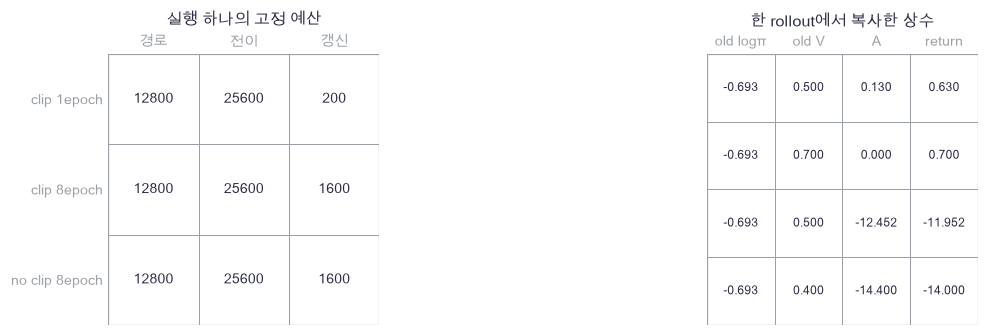

In [31]:
plot_ppo_protocol(protocol_budgets, names, protocol_stored)

🔍 **확인** · 여러 epoch가 더 좋아 보여도 계산 갱신을 더 많이 쓴 비교임을 함께 읽습니다. clip 유무의8epoch 비교는 optimizer 예산도 같지만, 정책이 바뀌면 이후의 경로와 old 분포도 달라지므로 모든 실행이 같은 전이 데이터를 본 것은 아닙니다.

In [32]:
def sample_ppo_paths(theta,count,rng):
    """고정된현재정책에서실제두전이경로를수집합니다. 반환state/action/reward:(B,2)."""
    # 쓰는 것: ppo_policy (위 절의 정의·실행 셀)
    policy,log_probabilities = ppo_policy(theta,np.eye(3))
    uniforms = rng.random((count,2))
    first = (uniforms[:,0]>=policy[0,0]).astype(int)
    second_state = np.where(first==0,2,1)
    second = (uniforms[:,1]>=policy[second_state,0]).astype(int)
    states = np.column_stack([np.zeros(count,dtype=int),second_state])
    actions = np.column_stack([first,second])
    reward_table = np.array([[0.,0.],[2.,-14.],[.7,.7]])
    return states,actions,reward_table[states,actions]

In [33]:
def train_ppo(seed,epochs=8,clip=.2,updates=200,batch_size=64):
    """새rollout→old배치고정→fullbatch여러epoch→새rollout 순서의실제PPO학습과모든진단입니다."""
    # 쓰는 것: frozen_ppo_batch, ppo_exact, ppo_loss (위 절의 정의·실행 셀)
    # 1. 세설정에서같은초기값·상호작용예산을사용합니다. optimizer횟수는epoch에따라다릅니다.
    theta,critic = np.zeros((3,2)),np.zeros(3)
    rng = np.random.default_rng(seed)
    value,truth = ppo_exact(theta)
    history = [[0,value,np.sqrt(np.mean((critic-truth)**2)),0.,0.,0.]]
    observed,first_batch_epochs = [],[]
    for update in range(updates):
        states,actions,rewards = sample_ppo_paths(theta,batch_size,rng)
        data = frozen_ppo_batch(theta,critic,states,actions,rewards)
        # 2. 모든 epoch에서 같은 oldlogp·oldV·A·return을 씁니다.
        for epoch in range(epochs+1):
            loss,gradients,metrics = ppo_loss(theta,critic,data,clip)
            if update==0:
                first_batch_epochs.append([epoch,loss,metrics['kl'],metrics['outside'],metrics['saturated'],metrics['ratio_min'],metrics['ratio_max']])
            if epoch==epochs:
                break
            theta -= .05*gradients['theta']
            critic -= .4*gradients['critic']
        # 3. 갱신 뒤 모델을 old 분포와 비교하고, 정확 J는 학습에 사용하지 않습니다.
        value,truth = ppo_exact(theta)
        history.append([update+1,value,np.sqrt(np.mean((critic-truth)**2)),metrics['kl'],metrics['outside'],metrics['saturated']])
        observed.append(np.mean(rewards[:,0]+.9*rewards[:,1]))
    return theta,critic,np.array(history),np.array(observed),np.array(first_batch_epochs)

In [34]:
# 쓰는 것: BATCH_SIZE, REPEATS, UPDATES, settings (위 절의 정의·실행 셀)
histories,final_actors,observed_returns,epoch_audits = [],[],[],[]
for epochs,clip in settings:
    method_histories,actors,observed,audits = [],[],[],[]
    for repeat in range(REPEATS):
        theta,critic,history,returns,audit = train_ppo(58100+repeat,epochs,clip,UPDATES,BATCH_SIZE)
        method_histories.append(history)
        actors.append(theta)
        observed.append(returns)
        audits.append(audit)
    histories.append(np.stack(method_histories))
    final_actors.append(np.stack(actors))
    observed_returns.append(np.stack(observed))
    epoch_audits.append(audits)
histories,final_actors,observed_returns = np.stack(histories),np.stack(final_actors),np.stack(observed_returns)
print('실제3설정×3seed 완료 · 실행당25600전이 · optimizer200/1600/1600회')

실제3설정×3seed 완료 · 실행당25600전이 · optimizer200/1600/1600회


In [35]:
update_axis = histories[0,0,:,0]
exact_values = histories[:,:,:,1]
kl_records = histories[:,:,:,3]
outside_records = histories[:,:,:,4]
saturated_records = histories[:,:,:,5]
mean_metrics = [exact_values.mean(axis=1),kl_records.mean(axis=1),outside_records.mean(axis=1),saturated_records.mean(axis=1)]
first_audits = [audits[0] for audits in epoch_audits]

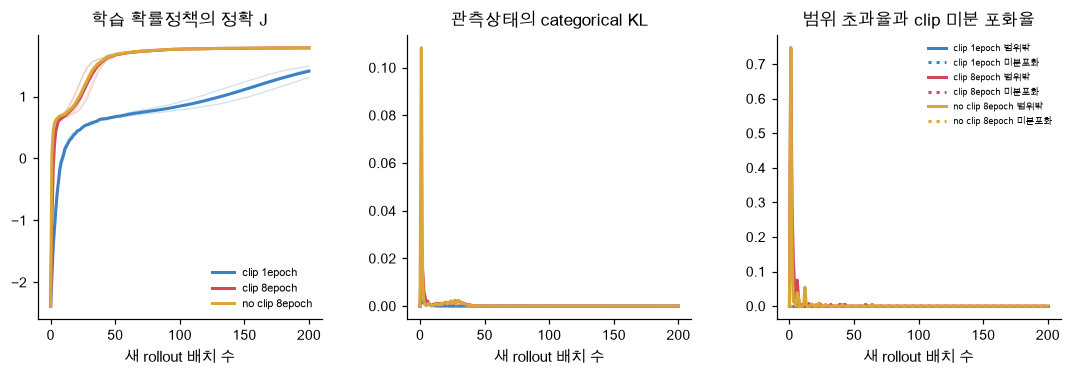

In [36]:
plot_ppo_learning(update_axis, exact_values, mean_metrics, names)

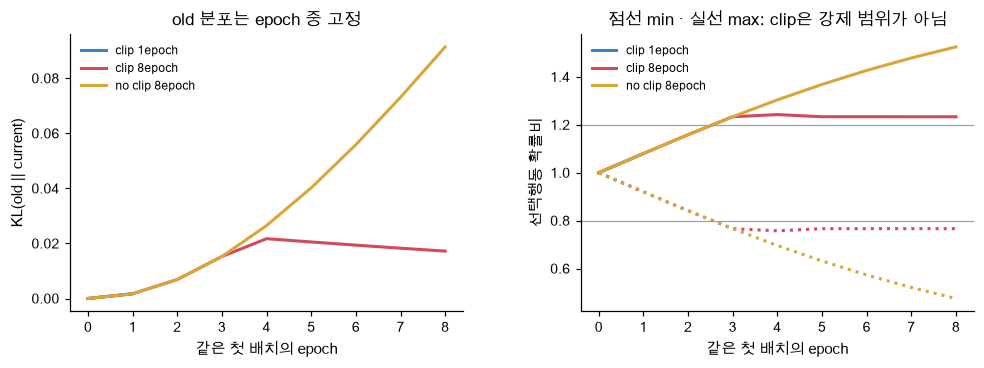

In [37]:
plot_ppo_epochs(first_audits, names)

🔍 **확인** · 정확 J의 얇은 선은 모든 seed, 굵은 선은3개 평균입니다. 나머지 진단 곡선은 seed 평균입니다. 첫 배치의 old 정책은 epoch 동안 고정되어 있으므로 KL이 어떻게 변하는지 직접 볼 수 있습니다. clip을 사용해도 실제 min/max ratio가.8·1.2를 넘어갈 수 있습니다. clip이 없는 쪽이 최종 J에서 비슷하거나 더 좋아도 그 결과를 그대로 남기며, 이 작은 환경에서 보편적인 안정성 순위를 결론내리지 않습니다.

In [38]:
# 쓰는 것: final_actors, histories, names, ppo_exact, sample_ppo_paths (위 절의 정의·실행 셀)
evaluation = np.zeros((3,3))
for method,name in enumerate(names):
    states,actions,rewards = sample_ppo_paths(final_actors[method,0],2048,np.random.default_rng(58999))
    returns = rewards[:,0]+.9*rewards[:,1]
    evaluation[method] = [returns.mean(),returns.std(ddof=1)/np.sqrt(2048),ppo_exact(final_actors[method,0])[0]]
    print(name,'각seed 최종J:',np.round(exact_values[method,:,-1],4),'최대관측KL:',np.round(kl_records[method].max(axis=1),4))
    print('첫배치 마지막 [범위밖,포화,minratio,maxratio]:',np.round(first_audits[method][-1,3:],4))
assert np.isfinite(histories).all(), '모든학습진단값은유한해야합니다'
np.testing.assert_allclose(saturated_records[2],0.)  # 검산:clip없는대조에는clip미분포화가없음
print('유한값·no-clip분기 통과 · 실제 성과에 대한 확률적 assert 없음')

clip 1epoch 각seed 최종J: [1.3058 1.491  1.4344] 최대관측KL: [0.0017 0.0028 0.003 ]
첫배치 마지막 [범위밖,포화,minratio,maxratio]: [0.   0.   0.92 1.08]
clip 8epoch 각seed 최종J: [1.7852 1.7879 1.7866] 최대관측KL: [0.0172 0.0175 0.0295]
첫배치 마지막 [범위밖,포화,minratio,maxratio]: [0.7344 0.6094 0.7666 1.2334]
no clip 8epoch 각seed 최종J: [1.7855 1.788  1.7871] 최대관측KL: [0.0914 0.0909 0.1427]
첫배치 마지막 [범위밖,포화,minratio,maxratio]: [0.7344 0.     0.4752 1.5248]
유한값·no-clip분기 통과 · 실제 성과에 대한 확률적 assert 없음


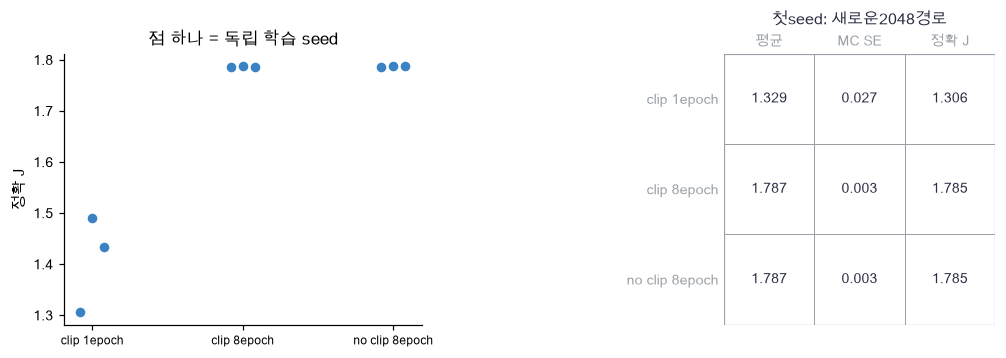

In [39]:
plot_ppo_final(names, exact_values[:,:,-1], evaluation)

🔍 **확인** · 마지막 표는 첫 학습 seed의 정책을 고정해 새2,048개 독립 경로로 평가한 평균·MC SE입니다. 세 학습 seed 차이의 불확실성과는 다른 대상입니다. 평가 때 argmax로 바꾸지 않으므로 학습한 확률정책의 정확 J와 같은 대상을 비교합니다.

### ✏️ 연습 5 · epoch별 optimizer 예산

새 배치 수에 한 배치를 쓰는 epoch 수를 곱하세요.

In [40]:
def exercise_budget(batches, epochs):
    """epoch별 optimizer 예산의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return updates

In [41]:
def check_budget(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    assert fn(200,8)==1600, 'fullbatch8epoch를200번이면1600갱신입니다'
    print('PPO optimizer 예산 통과')

run_check(check_budget,exercise_budget,hint='환경 전이 수와 다른 예산입니다.')

☐ exercise_budget: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 환경 전이 수와 다른 예산입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updates = batches * epochs
```

</details>

## ✏️ 전체 연결 연습 A–D

clip의부호·entropy·old정책·평가축을확인합니다.

### ✏️ 연습 A · 좋은 행동의 포화 조건

A가 양수일 때 ratio가 upper를 넘는지 반환하세요.

In [42]:
def exercise_positive_clip(ratio, clip):
    """좋은 행동의 포화 조건의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return saturated

In [43]:
def check_positive_clip(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_array_equal(fn(np.array([.7,1.,1.3]),.2),[False,False,True])  # 검산:좋은행동은위쪽만포화
    print('양수 advantage 포화 통과')

run_check(check_positive_clip,exercise_positive_clip,hint='낮아진 확률을 복구하는 미분은 남습니다.')

☐ exercise_positive_clip: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 낮아진 확률을 복구하는 미분은 남습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
saturated = ratio > 1.0 + clip
```

</details>

### ✏️ 연습 B · 한 상태의 entropy

행동 확률과 log확률을 곱해 더한 뒤 부호를 바꾸세요.

In [44]:
def exercise_entropy(probabilities):
    """한 상태의 entropy의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return entropy

In [45]:
def check_entropy(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    np.testing.assert_allclose(fn(np.array([.5,.5])),np.log(2.))  # 검산:두균등행동entropy
    print('categorical entropy 통과')

run_check(check_entropy,exercise_entropy,hint='이번 입력은 모두 양수입니다.')

☐ exercise_entropy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 이번 입력은 모두 양수입니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
entropy = -np.sum(probabilities * np.log(probabilities))
```

</details>

### ✏️ 연습 C · old 확률비의 분모 보존

수집당시 log확률의 독립 배열을 만드세요.

In [46]:
def exercise_old_copy(log_probabilities):
    """old 확률비의 분모 보존의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return old

In [47]:
def check_old_copy(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    x=np.array([-.7,-.3])
    old=fn(x)
    x[0]=0.
    np.testing.assert_allclose(old,[-.7,-.3])  # 검산:현재배열변경뒤old보존
    print('old log확률 복사 통과')

run_check(check_old_copy,exercise_old_copy,hint='old를 매 epoch 현재 log확률로 덮어쓰지 않습니다.')

☐ exercise_old_copy: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: old를 매 epoch 현재 log확률로 덮어쓰지 않습니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
old = log_probabilities.copy()
```

</details>

### ✏️ 연습 D · 관측 상태의 정확 categorical KL

행동은합하고 관측 상태는평균하세요.

In [48]:
def exercise_kl(old_probabilities, old_log, current_log):
    """관측 상태의 정확 categorical KL의 핵심 식을 완성합니다."""
    raise NotImplementedError
    return kl

In [49]:
def check_kl(fn):
    """작은 독립 손계산으로 핵심 식을 검사합니다."""
    p=np.array([[.5,.5]])
    np.testing.assert_allclose(fn(p,np.log(p),np.log(np.array([[.8,.2]]))),.5*np.log(.5/.8)+.5*np.log(.5/.2))  # 검산:선택행동하나가아닌전체행동합
    print('관측 상태 categorical KL 통과')

run_check(check_kl,exercise_kl,hint='전체 환경의 상태방문분포 기대값과 구분합니다.')

☐ exercise_kl: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 전체 환경의 상태방문분포 기대값과 구분합니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
kl = np.mean(np.sum(old_probabilities * (old_log - current_log), axis=1))
```

</details>

## ✏️ 준비도: 네 가지로 확인합니다

- **설명:** old 배열 네 가지를 epoch 중 고정하는 이유와 PPO surrogate가 실제 J와 다른 이유를 말할 수 있나요?
- **수식:** A의 부호별 clip 가지와 entropy 미분을 전개하고 actor·value·entropy의 분모를 구분할 수 있나요?
- **구현:** clip 경계를 피한 전체 중심차분, old 배열 불변, 종료·수집 경계 검산을 구현할 수 있나요?
- **변형 검산:** epoch 수를 늘렸을 때 환경 예산과 optimizer 예산, ratio 범위·KL·return을 함께 비교할 수 있나요?

## 📎 참고: 원자료와 이후 연결

- Schulman 외, [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347): 새 데이터 수집과 surrogate 최적화를 번갈아 수행하는 PPO 원자료입니다.
- [Spinning Up PPO 설명](https://spinningup.openai.com/en/latest/algorithms/ppo.html): advantage 부호별 clipped surrogate의 의미를 확인할 수 있습니다. PPO-Clip 자체는 KL hard constraint가 아닙니다.
- 이 단원은 full-batch SGD·별도 선형 actor/critic·할인된 episode 평균 actor/entropy를 쓰며, value clipping·advantage 정규화·KL 조기 중단은 생략했습니다. 이런 구현 규약은 실험을 비교할 때 함께 맞춰야 합니다.
- 이후 연속 행동·계획·오프라인 데이터·선호 보상은 [전체 학습 경로](../../docs/CURRICULUM.md)에서 이어집니다. 이산 행동의 확률 합을 먼저 검산했으므로 연속 밀도나 토큰 보상으로 바뀔 때 무엇을 다시 확인해야 하는지 구분할 수 있습니다.